<a href="https://colab.research.google.com/github/Amirthavarshini18/Product_reviewAnalysis/blob/main/Product_review.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving ReviewLens_Product_Review_Insight_Dataset.zip to ReviewLens_Product_Review_Insight_Dataset.zip


In [ ]:
import os
import zipfile
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
zip_path = "/content/ReviewLens_Product_Review_Insight_Dataset.zip"
folder = "/content/ReviewLens_Dataset"

with zipfile.ZipFile(zip_path, "r") as zip_file:
    zip_file.extractall(folder)
csv_files = {}
for root, folders, files in os.walk(folder):
    for file in files:
        if file.lower().endswith(".csv"):
            csv_files[file.lower()] = os.path.join(root, file)

reviews = pd.read_csv(csv_files["reviews.csv"])
products = pd.read_csv(csv_files["products.csv"])
sellers = pd.read_csv(csv_files["sellers.csv"])
orders = pd.read_csv(csv_files["orders.csv"])
support = pd.read_csv(csv_files["support.csv"])

print("All five datasets loaded successfully!")

All five datasets loaded successfully!


In [ ]:

datasets = {
    "Reviews": reviews,
    "Products": products,
    "Sellers": sellers,
    "Orders": orders,
    "Support": support
}
for name, data in datasets.items():
    print("\n---", name, "---")
    print("Rows and columns:", data.shape)
    print("Column names:", data.columns.tolist())
    print("\nData types:")
    print(data.dtypes)
    print("\nMissing values:")
    print(data.isnull().sum())
    print("Duplicate rows:", data.duplicated().sum())
    display(data.head())



--- Reviews ---
Rows and columns: (608, 7)
Column names: ['review_id', 'order_id', 'product_id', 'rating', 'review_length', 'verified_flag', 'date']

Data types:
review_id         object
order_id          object
product_id        object
rating           float64
review_length      int64
verified_flag     object
date              object
dtype: object

Missing values:
review_id         0
order_id          0
product_id        0
rating           16
review_length     0
verified_flag     0
date              0
dtype: int64
Duplicate rows: 8


,review_id,order_id,product_id,rating,review_length,verified_flag,date
0,R0001,O0031,P062,5.0,331,No,2025-03-08
1,R0002,O0337,P051,4.0,40,Yes,2025-07-25
2,R0003,O0578,P011,5.0,331,Yes,2025-12-26
3,R0004,O0518,P028,5.0,348,Yes,2025-08-06
4,R0005,O0322,P021,4.0,341,Yes,2026-06-05



--- Products ---
Rows and columns: (80, 6)
Column names: ['product_id', 'product_name', 'category', 'brand', 'price_band', 'seller_id']

Data types:
product_id      object
product_name    object
category        object
brand           object
price_band      object
seller_id       object
dtype: object

Missing values:
product_id      0
product_name    0
category        0
brand           0
price_band      0
seller_id       0
dtype: int64
Duplicate rows: 0


,product_id,product_name,category,brand,price_band,seller_id
0,P001,Product 001,Grocery,NovaTech,Mid-range,S017
1,P002,Product 002,Fashion,UrbanThread,Mid-range,S003
2,P003,Product 003,Beauty,NovaTech,Budget,S013
3,P004,Product 004,Home & Kitchen,NovaTech,Mid-range,S017
4,P005,Product 005,Fashion,PureNest,Budget,S005



--- Sellers ---
Rows and columns: (18, 4)
Column names: ['seller_id', 'seller', 'region', 'tenure_years']

Data types:
seller_id       object
seller          object
region          object
tenure_years     int64
dtype: object

Missing values:
seller_id       0
seller          0
region          0
tenure_years    0
dtype: int64
Duplicate rows: 0


,seller_id,seller,region,tenure_years
0,S001,Seller 01,South,4
1,S002,Seller 02,East,6
2,S003,Seller 03,South,8
3,S004,Seller 04,East,5
4,S005,Seller 05,North,10



--- Orders ---
Rows and columns: (650, 7)
Column names: ['order_id', 'product_id', 'seller_id', 'delivery_days', 'discount_pct', 'return_flag', 'order_date']

Data types:
order_id         object
product_id       object
seller_id        object
delivery_days     int64
discount_pct      int64
return_flag      object
order_date       object
dtype: object

Missing values:
order_id         0
product_id       0
seller_id        0
delivery_days    0
discount_pct     0
return_flag      0
order_date       0
dtype: int64
Duplicate rows: 0


,order_id,product_id,seller_id,delivery_days,discount_pct,return_flag,order_date
0,O0001,P043,S013,3,26,No,2025-11-11
1,O0002,P044,S012,4,29,No,2026-02-03
2,O0003,P033,S009,1,39,No,2025-03-08
3,O0004,P046,S009,3,35,No,2025-03-02
4,O0005,P065,S017,4,27,No,2026-03-29



--- Support ---
Rows and columns: (160, 5)
Column names: ['support_id', 'order_id', 'complaint_category', 'resolution', 'resolution_days']

Data types:
support_id            object
order_id              object
complaint_category    object
resolution            object
resolution_days        int64
dtype: object

Missing values:
support_id            0
order_id              0
complaint_category    0
resolution            0
resolution_days       0
dtype: int64
Duplicate rows: 0


,support_id,order_id,complaint_category,resolution,resolution_days
0,C0001,O0014,Refund delay,Resolved,13
1,C0002,O0267,Packaging,Resolved,0
2,C0003,O0038,Refund delay,Resolved,8
3,C0004,O0595,Refund delay,Escalated,9
4,C0005,O0426,Packaging,Resolved,5


In [ ]:

# 1. Missing ratings
print("1. Missing ratings:")
print(reviews["rating"].isna().sum())

# 2. Duplicate reviews
print("\n2. Duplicate reviews:")
print("Duplicate rows:", reviews.duplicated().sum())
print("Repeated review IDs:", reviews["review_id"].duplicated().sum())

# 3. Inconsistent product categories
print("\n3. Original categories:")
print(products["category"].value_counts(dropna=False))

print("\nCategories after standardizing text:")
print(
    products["category"]
    .astype("string")
    .str.strip()
    .str.lower()
    .value_counts(dropna=False)
)

lengths = pd.to_numeric(reviews["review_length"], errors="coerce")
q1 = lengths.quantile(0.25)
q3 = lengths.quantile(0.75)
iqr = q3 - q1

extreme_reviews = reviews[
    (lengths < q1 - 1.5 * iqr) |
    (lengths > q3 + 1.5 * iqr)
]

print("\n4. Extreme review lengths:", len(extreme_reviews))
display(extreme_reviews[["review_id", "review_length"]])

# 5. Unmatched product IDs
unmatched = reviews[
    ~reviews["product_id"].isin(products["product_id"])
]

print("\n5. Reviews with unmatched product IDs:", len(unmatched))
display(unmatched[["review_id", "product_id"]])

1. Missing ratings:
16

2. Duplicate reviews:
Duplicate rows: 8
Repeated review IDs: 8

3. Original categories:
category
Grocery           15
Home & Kitchen    14
Sports            13
Beauty            12
Fashion           11
Electronics        7
 electronics       5
beauty             1
Fashion            1
HOME & KITCHEN     1
Name: count, dtype: int64

Categories after standardizing text:
category
grocery           15
home & kitchen    15
sports            13
beauty            13
fashion           12
electronics       12
Name: count, dtype: Int64

4. Extreme review lengths: 5


,review_id,review_length
120,R0121,5000
162,R0163,2500
212,R0213,5000
469,R0470,5000
566,R0567,5000



5. Reviews with unmatched product IDs: 7


,review_id,product_id
177,R0178,PX005
224,R0225,PX002
364,R0365,PX006
376,R0377,PX001
444,R0445,PX003
466,R0467,PX004
471,R0472,PX007


In [ ]:

# Keep a copy of the original data
clean_reviews = reviews.copy()
clean_products = products.copy()

# Remove exact duplicate rows
clean_reviews = clean_reviews.drop_duplicates()

# Convert ratings to numbers and remove missing ratings
clean_reviews["rating"] = pd.to_numeric(
    clean_reviews["rating"], errors="coerce"
)
clean_reviews = clean_reviews.dropna(subset=["rating"])

# Standardize category names
clean_products["category"] = (
    clean_products["category"]
    .astype("string")
    .str.strip()
    .str.lower()
)

# Identify extreme review lengths without deleting them
clean_reviews["review_length"] = pd.to_numeric(
    clean_reviews["review_length"], errors="coerce"
)

lengths = clean_reviews["review_length"]
q1 = lengths.quantile(0.25)
q3 = lengths.quantile(0.75)
iqr = q3 - q1

clean_reviews["extreme_length"] = (
    (lengths < q1 - 1.5 * iqr) |
    (lengths > q3 + 1.5 * iqr)
)

# Exclude reviews whose product IDs do not exist
clean_reviews = clean_reviews[
    clean_reviews["product_id"].isin(clean_products["product_id"])
].copy()

print("Data cleaning completed.")
print("Reviews remaining:", len(clean_reviews))
print("Products:", len(clean_products))
print("Extreme-length reviews flagged:",
      clean_reviews["extreme_length"].sum())


Data cleaning completed.
Reviews remaining: 577
Products: 80
Extreme-length reviews flagged: 4


In [ ]:

# Add product information to reviews
analysis = clean_reviews.merge(
    clean_products.rename(columns={"seller_id": "product_seller_id"}),
    on="product_id",
    how="left"
)

# Add order information
order_columns = [
    "order_id", "delivery_days", "seller_id",
    "return_flag", "discount_pct", "order_date"
]

analysis = analysis.merge(
    orders[order_columns],
    on="order_id",
    how="left",
    validate="many_to_one"
)

# Add seller names and details
analysis = analysis.merge(
    sellers,
    on="seller_id",
    how="left",
    validate="many_to_one"
)

# Summarize support complaints for each order
support_summary = support.groupby("order_id").agg(
    complaint_category=(
        "complaint_category",
        lambda values: ", ".join(values.dropna().astype(str).unique())
    )
).reset_index()

analysis = analysis.merge(
    support_summary,
    on="order_id",
    how="left",
    validate="many_to_one"
)

print("Combined dataset created.")
print("Rows and columns:", analysis.shape)
display(analysis.head())

Combined dataset created.
Rows and columns: (577, 22)


,review_id,order_id,product_id,rating,review_length,verified_flag,date,extreme_length,product_name,category,...,product_seller_id,delivery_days,seller_id,return_flag,discount_pct,order_date,seller,region,tenure_years,complaint_category
0,R0001,O0031,P062,5.0,331,No,2025-03-08,False,Product 062,fashion,...,S006,5,S004,Yes,36,2026-03-06,Seller 04,East,5,NaN
1,R0002,O0337,P051,4.0,40,Yes,2025-07-25,False,Product 051,home & kitchen,...,S012,2,S016,No,30,2025-05-28,Seller 16,East,3,NaN
2,R0003,O0578,P011,5.0,331,Yes,2025-12-26,False,Product 011,fashion,...,S015,4,S012,No,2,2025-12-14,Seller 12,North,4,NaN
3,R0004,O0518,P028,5.0,348,Yes,2025-08-06,False,Product 028,beauty,...,S002,5,S007,Yes,21,2025-12-26,Seller 07,South,9,NaN
4,R0005,O0322,P021,4.0,341,Yes,2026-06-05,False,Product 021,electronics,...,S012,6,S016,No,8,2025-03-19,Seller 16,East,3,NaN


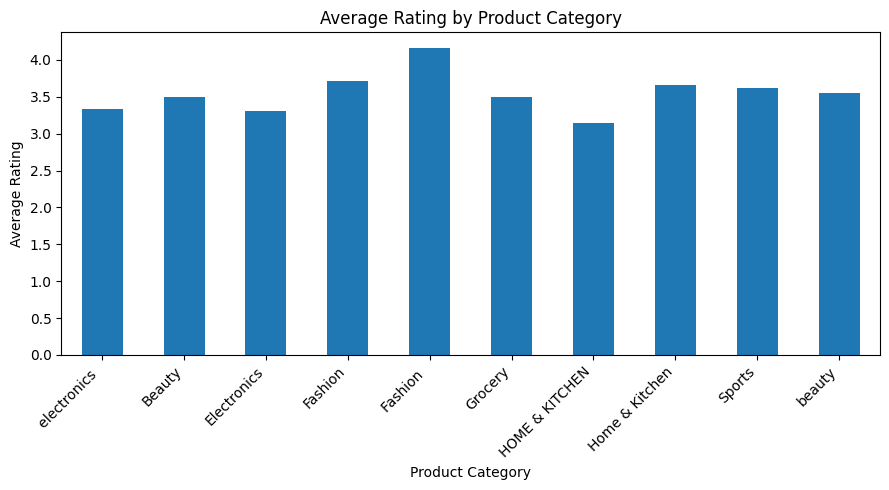

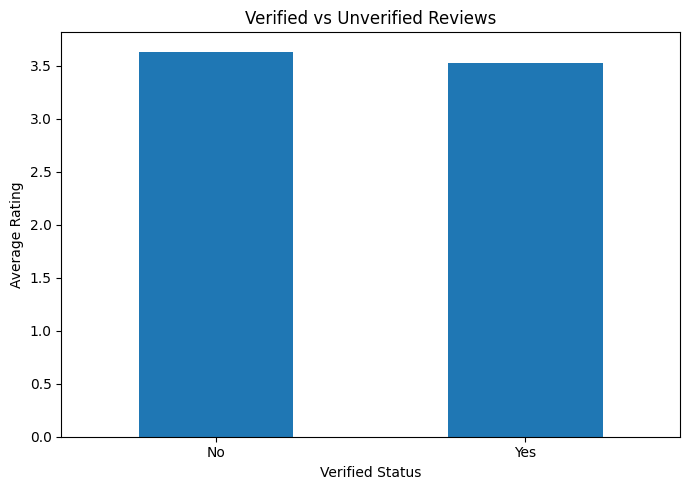

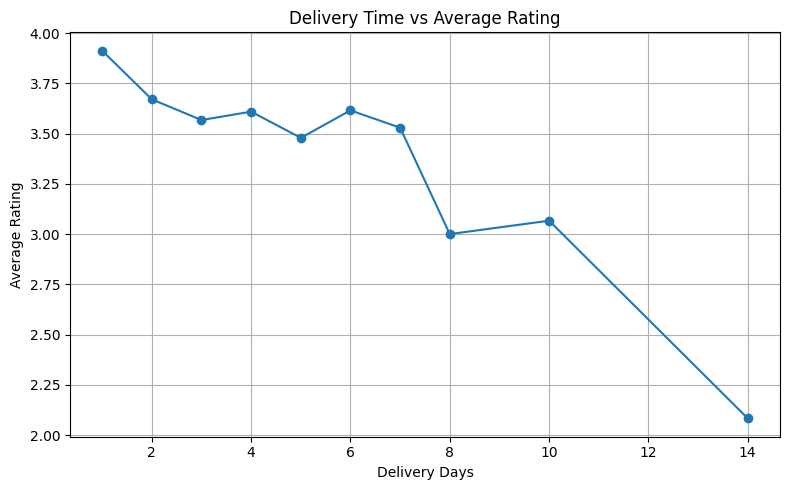

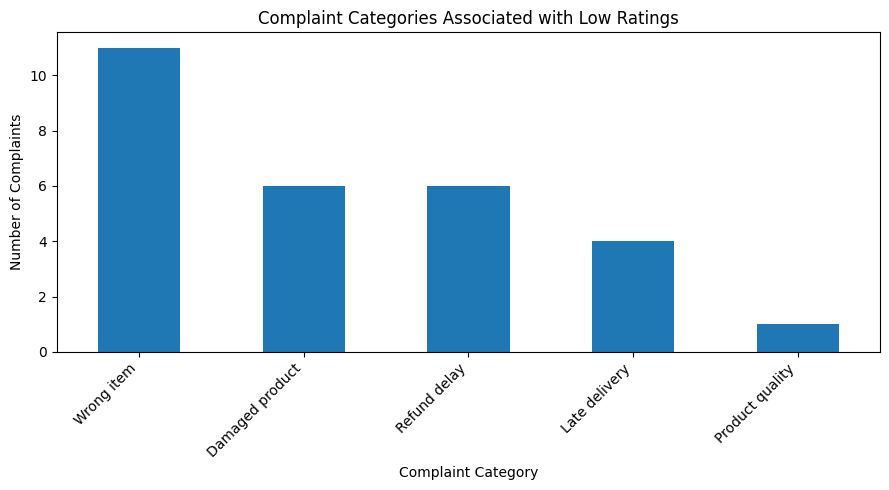

Complaint counts associated with low ratings:
complaint_category
Wrong item         11
Damaged product     6
Refund delay        6
Late delivery       4
Product quality     1
Name: count, dtype: int64


In [14]:

import pandas as pd
import matplotlib.pyplot as plt

# 1. Merge reviews with product details
data = reviews.merge(
    products[["product_id", "category"]],
    on="product_id",
    how="left"
)

# 2. Merge delivery and return details
data = data.merge(
    orders[["order_id", "delivery_days", "return_flag"]],
    on="order_id",
    how="left",
    suffixes=("", "_order")
)

# Convert rating to numeric
data["rating"] = pd.to_numeric(data["rating"], errors="coerce")

# VISUALISATION 1: Average rating by product category
category_rating = data.groupby("category")["rating"].mean().dropna()

plt.figure(figsize=(9, 5))
category_rating.plot(kind="bar")
plt.title("Average Rating by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Average Rating")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


# VISUALISATION 2: Verified vs Unverified reviews
verified_rating = data.groupby("verified_flag")["rating"].mean().dropna()

plt.figure(figsize=(7, 5))
verified_rating.plot(kind="bar")
plt.title("Verified vs Unverified Reviews")
plt.xlabel("Verified Status")
plt.ylabel("Average Rating")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# VISUALISATION 3: Delivery time vs average rating
delivery_rating = data.groupby("delivery_days")["rating"].mean().dropna()

plt.figure(figsize=(8, 5))
delivery_rating.sort_index().plot(kind="line", marker="o")
plt.title("Delivery Time vs Average Rating")
plt.xlabel("Delivery Days")
plt.ylabel("Average Rating")
plt.grid(True)
plt.tight_layout()
plt.show()


# VISUALISATION 4: Complaint categories linked to low ratings
low_ratings = data[
    data["rating"].isin([1, 2])
][["order_id", "rating"]].dropna()

low_complaints = low_ratings.merge(
    support[["order_id", "complaint_category"]].dropna(),
    on="order_id",
    how="inner"
)

complaints = low_complaints["complaint_category"].value_counts()

plt.figure(figsize=(9, 5))

if complaints.empty:
    print("No matching complaints found for low-rated reviews.")
else:
    complaints.plot(kind="bar")
    plt.title("Complaint Categories Associated with Low Ratings")
    plt.xlabel("Complaint Category")
    plt.ylabel("Number of Complaints")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

print("Complaint counts associated with low ratings:")
print(complaints)

In [15]:
0k import openpyxl
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.utils.dataframe import dataframe_to_rows
from google.colab import files

# Initialize Workbook
wb = openpyxl.Workbook()

# Setup summary sheet
ws_summary = wb.active
ws_summary.title = "Executive Dashboard"
ws_summary.views.sheetView[0].showGridLines = True

# 1. Colors & Styles
primary_color = "1F4E79"
accent_color = "DDEBF7"
font_family = "Segoe UI"

title_font = Font(name=font_family, size=18, bold=True, color="FFFFFF")
section_font = Font(name=font_family, size=12, bold=True, color=primary_color)
header_font = Font(name=font_family, size=11, bold=True, color="FFFFFF")
body_font = Font(name=font_family, size=11, color="000000")
kpi_num_font = Font(name=font_family, size=16, bold=True, color="1F4E79")
kpi_lbl_font = Font(name=font_family, size=9, bold=True, color="595959")

title_fill = PatternFill(start_color=primary_color, end_color=primary_color, fill_type="solid")
header_fill = PatternFill(start_color=primary_color, end_color=primary_color, fill_type="solid")
kpi_fill = PatternFill(start_color=accent_color, end_color=accent_color, fill_type="solid")

thin_border_side = Side(border_style="thin", color="D3D3D3")
thin_border = Border(left=thin_border_side, right=thin_border_side, top=thin_border_side, bottom=thin_border_side)

# Write Dashboard Header
ws_summary.merge_cells("A1:H2")
title_cell = ws_summary["A1"]
title_cell.value = "ReviewLens Product Performance & Support Dashboard"
title_cell.font = title_font
title_cell.fill = title_fill
title_cell.alignment = Alignment(horizontal="center", vertical="center")

# 2. Add Key KPI Cards (Row 4-5)
kpis = [
    ("Total Reviews", len(analysis), "A4", "B5"),
    ("Average Rating", f"{analysis['rating'].mean():.2f} ★", "C4", "D5"),
    ("Avg Delivery Days", f"{analysis['delivery_days'].mean():.1f} Days", "E4", "F5"),
    ("Return Rate", f"{(analysis['return_flag'] == 'Yes').mean() * 100:.1f}%", "G4", "H5")
]

for label, val, start, end in kpis:
    ws_summary.merge_cells(f"{start}:{end}")
    cell = ws_summary[start]
    cell.value = f"{label}\n{val}"
    cell.font = Font(name=font_family, size=11, bold=True, color="1F4E79")
    cell.fill = kpi_fill
    cell.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)

    # Apply borders
    start_col, start_row = openpyxl.utils.coordinate_to_tuple(start)
    end_col, end_row = openpyxl.utils.coordinate_to_tuple(end)
    for r in range(start_row, end_row + 1):
        for c in range(start_col, end_col + 1):
            ws_summary.cell(row=r, column=c).border = thin_border

# 3. Section 1: Ratings and Performance by Category
ws_summary["A7"] = "Product Category Insights"
ws_summary["A7"].font = section_font

# Generate stats group
cat_stats = analysis.groupby("category").agg(
    Total_Reviews=("review_id", "count"),
    Average_Rating=("rating", "mean"),
    Avg_Delivery_Days=("delivery_days", "mean")
).reset_index()

# Write headers
headers_cat = ["Category", "Total Reviews", "Avg Rating", "Avg Delivery Days"]
for col_idx, text in enumerate(headers_cat, 1):
    cell = ws_summary.cell(row=8, column=col_idx, value=text)
    cell.font = header_font
    cell.fill = header_fill
    cell.alignment = Alignment(horizontal="left" if col_idx == 1 else "center")

# Write values
for row_idx, row_data in enumerate(dataframe_to_rows(cat_stats, index=False, header=False), 9):
    for col_idx, val in enumerate(row_data, 1):
        cell = ws_summary.cell(row=row_idx, column=col_idx, value=val)
        cell.font = body_font
        cell.border = thin_border
        if col_idx == 1:
            cell.value = str(val).title()
        elif col_idx == 3:
            cell.number_format = "0.00"
        elif col_idx == 4:
            cell.number_format = "0.0"

# 4. Section 2: Support Complaint Analysis
start_complaints_row = 11 + len(cat_stats)
ws_summary.cell(row=start_complaints_row, column=1, value="Key Customer Pain Points").font = section_font

headers_comp = ["Complaint Category", "Volume of Complaints"]
for col_idx, text in enumerate(headers_comp, 1):
    cell = ws_summary.cell(row=start_complaints_row + 1, column=col_idx, value=text)
    cell.font = header_font
    cell.fill = header_fill
    cell.alignment = Alignment(horizontal="left" if col_idx == 1 else "center")

comp_counts = support["complaint_category"].value_counts().reset_index()
for row_idx, row_data in enumerate(dataframe_to_rows(comp_counts, index=False, header=False), start_complaints_row + 2):
    for col_idx, val in enumerate(row_data, 1):
        cell = ws_summary.cell(row=row_idx, column=col_idx, value=val)
        cell.font = body_font
        cell.border = thin_border

# Add the raw analysis data to a separate tab
ws_data = wb.create_sheet(title="Cleaned Data")
ws_data.views.sheetView[0].showGridLines = True

for r_idx, r in enumerate(dataframe_to_rows(analysis, index=False, header=True), 1):
    for c_idx, value in enumerate(r, 1):
        cell = ws_data.cell(row=r_idx, column=c_idx, value=value)
        if r_idx == 1:
            cell.font = header_font
            cell.fill = header_fill
        else:
            cell.font = body_font
            cell.border = thin_border

# Auto-fit columns across sheets
for sheet in wb.worksheets:
    for col in sheet.columns:
        max_len = 0
        col_letter = openpyxl.utils.get_column_letter(col[0].column)
        for cell in col:
            if cell.value:
                max_len = max(max_len, len(str(cell.value)))
        sheet.column_dimensions[col_letter].width = max(max_len + 3, 12)

# Save Workbook and download
excel_path = "/content/ReviewLens_Ecom_Dashboard.xlsx"
wb.save(excel_path)
print("Excel file created successfully. Triggering download...")
files.download(excel_path)


Excel file created successfully. Triggering download...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>